# 08 - Advanced Models and Hyperparameter Tuning

Goal: try stronger machine-learning models on the **same data, same 13 features and same patient-wise split** as notebooks 02-06, tune them, and see if any beats the old Random Forest (notebooks 02-07 are not changed).

| Model | Why we try it |
|---|---|
| Histogram Gradient Boosting | Boosting builds trees one after another, each fixing the mistakes of the last. Same family as XGBoost / LightGBM |
| Random Forest (tuned) | The old Random Forest only tried 2 settings. Here it gets the same wide search as the others, so the comparison is fair |
| Extra Trees | Forest with random split points, less overfit |
| XGBoost, LightGBM | Used automatically **if the libraries are installed** (`pip install xgboost lightgbm`), skipped otherwise |

**Tuning method:** random search. Each trial is trained on the train set and scored on the **validation** set (mean of ROC-AUC and PR-AUC). The test set is never used for tuning.

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from src import config as C
from src.features import get_xy
from src import advanced_models as A
from src.pipeline import predict_proba
from src.evaluation import evaluate_and_save, add_high_recall_point, plot_curves

df = pd.read_parquet(C.CLEAN_PATH)
X_train, y_train, _ = get_xy(df, "train")
X_val, y_val, _ = get_xy(df, "val")
X_test, y_test, _ = get_xy(df, "test")
print(X_train.shape, X_val.shape, X_test.shape)
print("Models that will run:", list(A.ADV_MODELS))
print("Skipped (library not installed):", A.OPTIONAL_MISSING)

(384548, 13) (81129, 13) (80445, 13)
Models that will run: ['hist_gradient_boosting', 'random_forest_tuned', 'extra_trees']
Skipped (library not installed): ['xgboost', 'lightgbm']


## Tune, evaluate and save every model
For each model: random search, then the best settings are scored on validation and test. Results are saved in `results/<model>.json`, so notebook 09 can compare them with the old models.


===== hist_gradient_boosting  (175 s) =====
best settings: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 300, 'max_depth': 6, 'learning_rate': 0.02, 'l2_regularization': 10.0, 'class_weight': 'balanced'}


,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,class_weight,val_roc_auc,val_pr_auc,val_score,seconds
0,100,15,300,6,0.02,10.0,balanced,0.7762,0.1072,0.4417,7.9
1,100,15,400,3,0.03,5.0,balanced,0.7738,0.1090,0.4414,8.0
2,100,15,300,5,0.05,10.0,NaN,0.7774,0.1042,0.4408,6.4
3,200,15,200,3,0.08,0.0,balanced,0.7728,0.1080,0.4404,4.4
4,200,63,100,3,0.08,30.0,NaN,0.7741,0.1063,0.4402,2.8


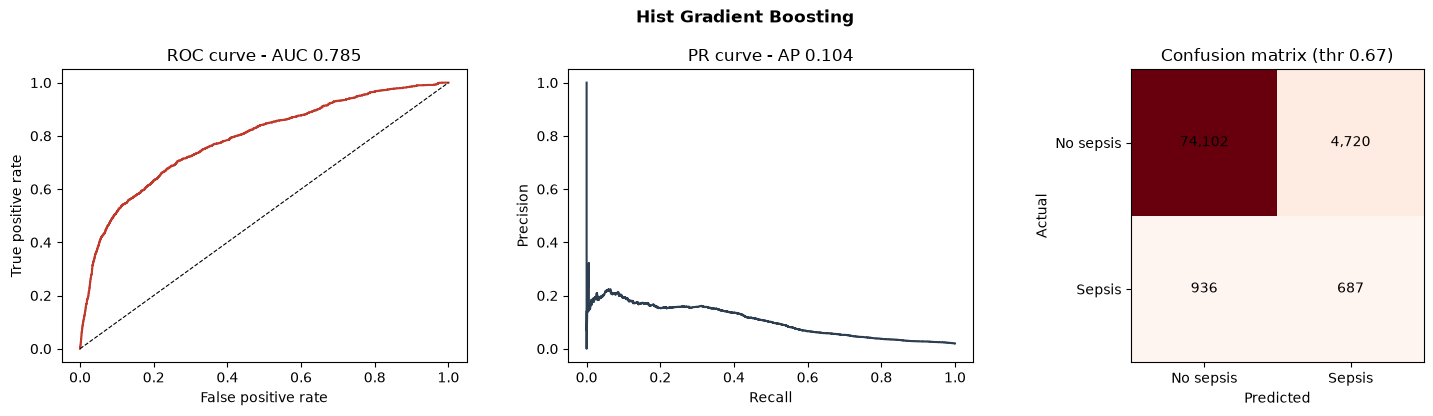


===== random_forest_tuned  (255 s) =====
best settings: {'n_estimators': 100, 'min_samples_leaf': 200, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 8}


,n_estimators,min_samples_leaf,max_samples,max_features,max_depth,val_roc_auc,val_pr_auc,val_score,seconds
0,200,100,0.3,sqrt,10,0.7726,0.1020,0.4373,23.2
1,100,200,0.5,0.5,8,0.7737,0.1010,0.4373,17.8
2,200,200,0.5,0.5,10,0.7723,0.0994,0.4359,42.9
3,100,200,0.3,sqrt,6,0.7651,0.1028,0.4340,10.6
4,100,20,0.3,0.5,6,0.7661,0.1011,0.4336,11.8


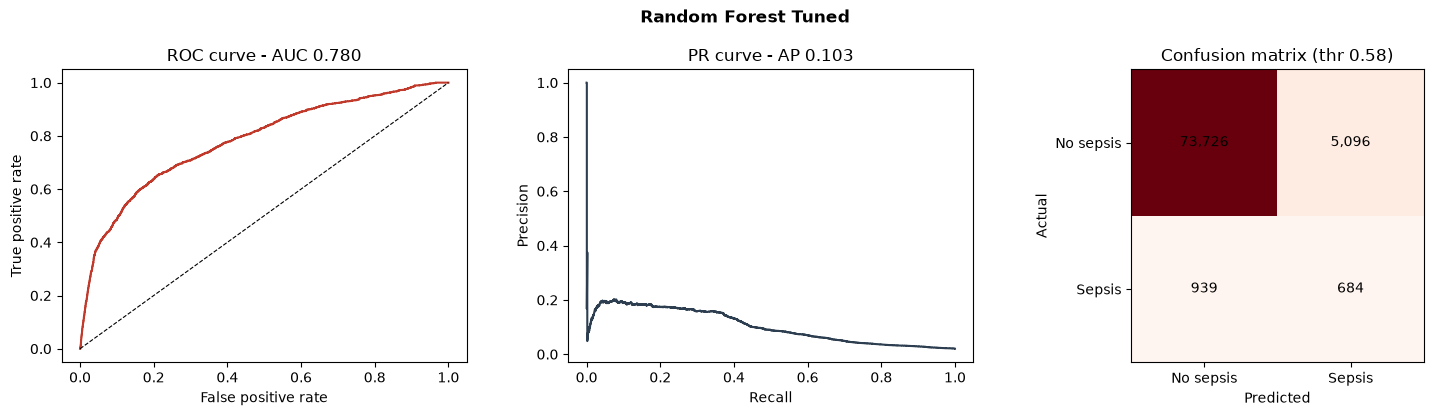


===== extra_trees  (119 s) =====
best settings: {'n_estimators': 100, 'min_samples_leaf': 100, 'max_features': 0.5, 'max_depth': 14, 'class_weight': 'balanced_subsample'}


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,val_roc_auc,val_pr_auc,val_score,seconds
0,100,100,0.5,14,balanced_subsample,0.7563,0.1022,0.4293,19.5
1,100,50,sqrt,14,NaN,0.7515,0.1038,0.4276,11.4
2,100,20,0.5,10,NaN,0.7454,0.1025,0.4240,12.7
3,100,20,sqrt,10,balanced_subsample,0.7399,0.0997,0.4198,8.9
4,100,100,sqrt,14,balanced_subsample,0.7427,0.0956,0.4191,10.7


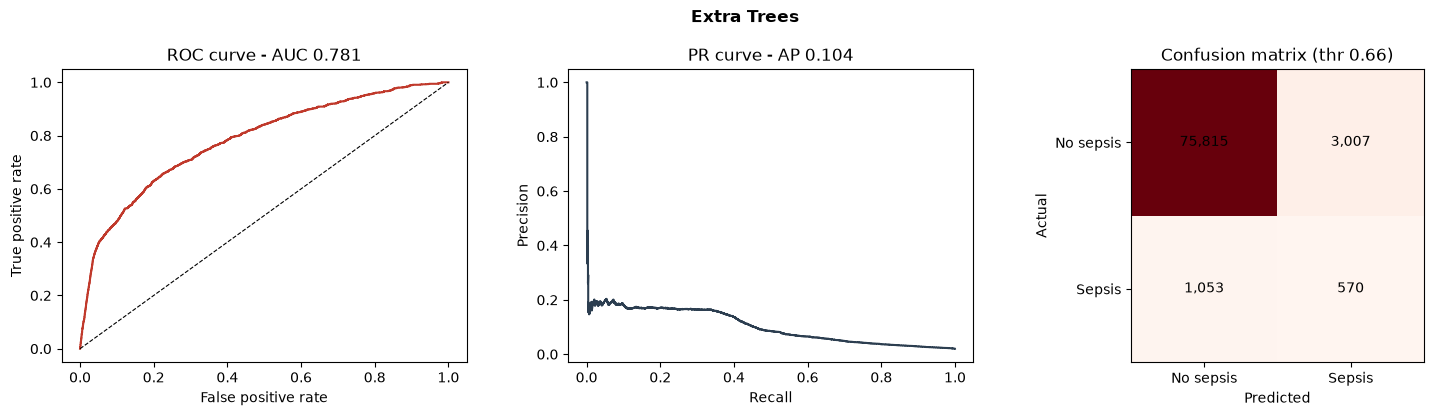

In [2]:
N_ITER = {"hist_gradient_boosting": 30, "random_forest_tuned": 10, "extra_trees": 10,
          "xgboost": 30, "lightgbm": 30}
fitted, summary = {}, []
for name in A.ADV_MODELS:
    t = time.time()
    model, best_params, tuning = A.tune_model(name, X_train, y_train, X_val, y_val,
                                              n_iter=N_ITER[name], verbose=False)
    p_val, p_test = predict_proba(model, X_val), predict_proba(model, X_test)
    res = evaluate_and_save(name, y_val, p_val, y_test, p_test,
                            extra={"params": best_params, "tuning": A.table_records(tuning)})
    hr = add_high_recall_point(name, y_val, p_val, y_test, p_test)
    fitted[name] = model
    summary.append({"model": name, "trials": len(tuning),
                    "val_roc_auc": res["val"]["roc_auc"], "val_pr_auc": res["val"]["pr_auc"],
                    "test_roc_auc": res["test"]["roc_auc"], "test_pr_auc": res["test"]["pr_auc"],
                    "test_recall": res["test"]["recall"], "test_precision": res["test"]["precision"],
                    "test_f2": res["test"]["f2"],
                    "hs_recall": hr["test"]["recall"], "hs_precision": hr["test"]["precision"]})
    print(f"\n===== {name}  ({time.time()-t:.0f} s) =====")
    print("best settings:", best_params)
    display(tuning.head(5))
    plot_curves(y_test, p_test, name.replace("_", " ").title(), res["test"]["threshold"])

## Summary of the advanced models
`test_recall` is at the balanced (F2) threshold. `hs_recall` is the **high-sensitivity** operating point: the threshold is chosen on validation to catch at least 70% of sepsis rows. It finds more cases but gives more false alarms (lower precision).

In [3]:
summary_df = pd.DataFrame(summary).round(3)
summary_df

,model,trials,val_roc_auc,val_pr_auc,test_roc_auc,test_pr_auc,test_recall,test_precision,test_f2,hs_recall,hs_precision
0,hist_gradient_boosting,30,0.776,0.107,0.785,0.104,0.423,0.127,0.289,0.727,0.047
1,random_forest_tuned,10,0.774,0.101,0.780,0.103,0.421,0.118,0.279,0.715,0.045
2,extra_trees,10,0.756,0.102,0.781,0.104,0.351,0.159,0.283,0.723,0.045


## Feature importance (permutation)
Permutation importance shuffles one feature at a time on validation data and measures how much PR-AUC drops. It works for every model type, including boosting.

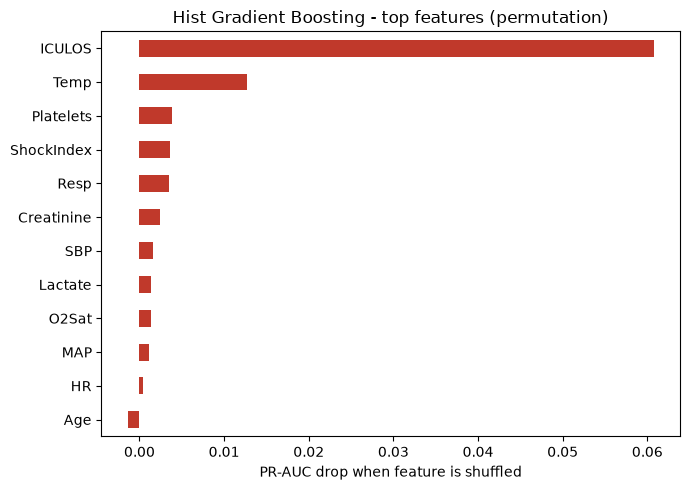

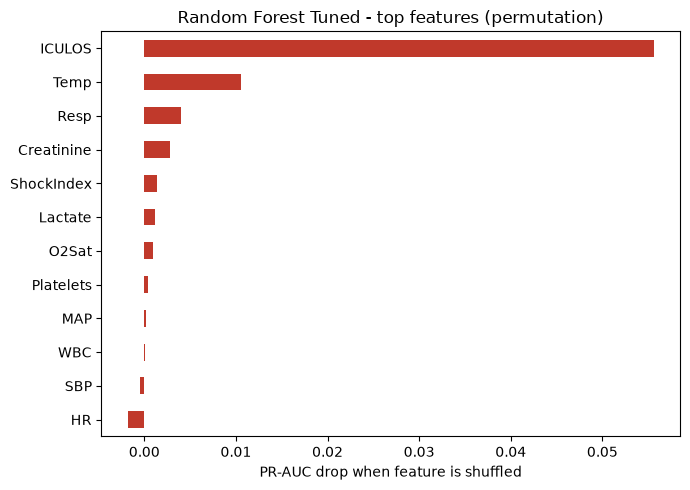

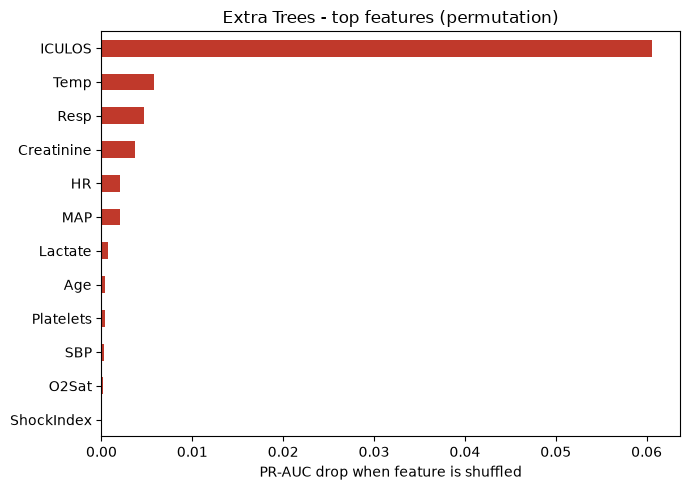

In [4]:
rng = np.random.RandomState(C.RANDOM_STATE)
idx = rng.choice(len(X_val), size=40000, replace=False)
Xs, ys = X_val.iloc[idx], y_val.iloc[idx]
for name, model in fitted.items():
    pi = permutation_importance(model, Xs, ys, scoring="average_precision", n_repeats=3,
                                random_state=C.RANDOM_STATE, n_jobs=1)
    imp = pd.Series(pi.importances_mean, index=X_val.columns).sort_values().tail(12)
    imp.plot.barh(figsize=(7, 5), color="#c0392b")
    plt.title(name.replace("_", " ").title() + " - top features (permutation)")
    plt.xlabel("PR-AUC drop when feature is shuffled")
    plt.tight_layout(); plt.savefig(C.FIG_DIR / f"{name}_importance.png", dpi=130); plt.show()

## Notes
- XGBoost / LightGBM run only when installed. On a machine with `pip install xgboost lightgbm`, re-running this notebook adds them automatically and notebook 09 will include them.
- The model is still judged only on validation for selection (notebook 09). Test numbers are reported at the end, never used to choose.